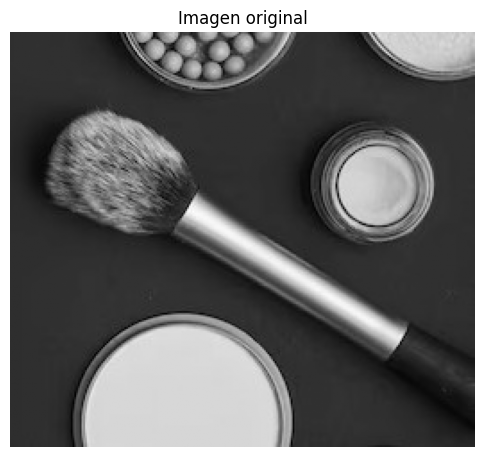

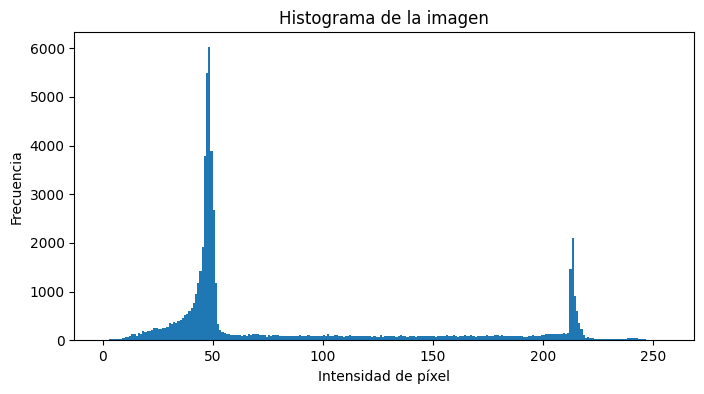

In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Cargar la imagen en escala de grises
imagen = cv2.imread('imagen_makeup.jpg', cv2.IMREAD_GRAYSCALE)

# Si tratará la imagen en color, incrustar el código necesario
# Mostrar la imagen original
plt.figure(figsize=(6, 6))
plt.imshow(imagen, cmap='gray')
plt.title('Imagen original')
plt.axis('off')
plt.show()

# Mostrar el histograma
plt.figure(figsize=(8, 4))
plt.hist(imagen.ravel(), bins=256, range=[0, 256])
plt.title('Histograma de la imagen')
plt.xlabel('Intensidad de píxel')
plt.ylabel('Frecuencia')
plt.show()

### Metodo Ostu

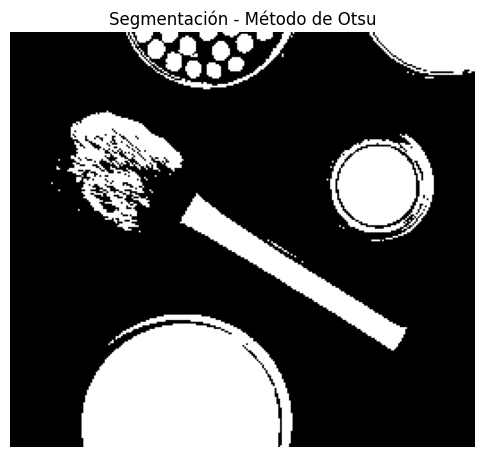

In [12]:
# Método de Otsu
_, imagen_otsu = cv2.threshold(imagen, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# Mostrar la imagen segmentada
plt.figure(figsize=(6, 6))
plt.imshow(imagen_otsu, cmap='gray')
plt.title('Segmentación - Método de Otsu') 
plt.axis('off')
plt.show()

### Metodo de entropia de kapur

Umbral de Kapur: 79


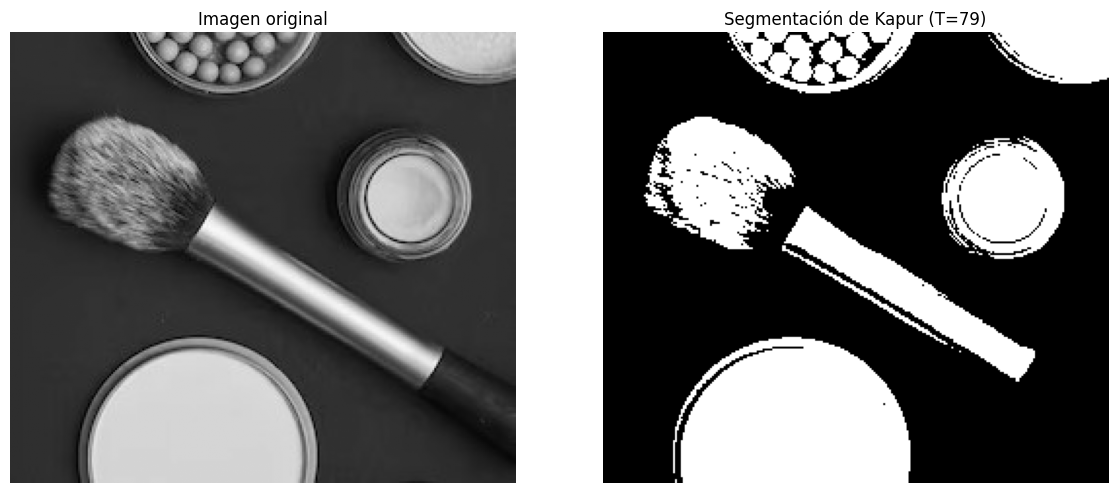

In [13]:
import numpy as np
import matplotlib.pyplot as plt

def entropia_kapur(histograma, total_pixeles):
    max_entropia = -np.inf
    umbral_optimo = 0

    # Probabilidades del histograma
    prob = histograma.astype(np.float64) / total_pixeles

    for t in range(256):

        # Clase 1: intensidades de 0 a t
        clase1 = prob[:t + 1]

        # Clase 2: intensidades de t+1 a 255
        clase2 = prob[t + 1:]

        p1 = np.sum(clase1)
        p2 = np.sum(clase2)

        # Evitar clases vacías
        if p1 == 0 or p2 == 0:
            continue

        # Normalizar las probabilidades de cada clase
        prob1 = clase1 / p1
        prob2 = clase2 / p2

        # Ignorar probabilidades iguales a cero
        prob1 = prob1[prob1 > 0]
        prob2 = prob2[prob2 > 0]

        # Entropías de Kapur
        entropia1 = -np.sum(prob1 * np.log(prob1))
        entropia2 = -np.sum(prob2 * np.log(prob2))

        # Kapur maximiza la suma de las entropías
        entropia_total = entropia1 + entropia2

        if entropia_total > max_entropia:
            max_entropia = entropia_total
            umbral_optimo = t

    return umbral_optimo


# Calcular histograma
histograma, _ = np.histogram(
    imagen, bins=256, range=(0, 256)
)
total_pixeles = imagen.size

# Calcular umbral
umbral_kapur = entropia_kapur(histograma, total_pixeles)

# Segmentar: fondo blanco y objeto negro
imagen_kapur = np.where(
    imagen > umbral_kapur, 255, 0
).astype(np.uint8)

print("Umbral de Kapur:", umbral_kapur)

# Mostrar resultados
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(imagen, cmap="gray", vmin=0, vmax=255)
plt.title("Imagen original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(imagen_kapur, cmap="gray", vmin=0, vmax=255)
plt.title(f"Segmentación de Kapur (T={umbral_kapur})")
plt.axis("off")

plt.tight_layout()
plt.show()

### Metodo minimo del histograma

Picos encontrados en el histograma: 4, 27
Umbral mínimo del histograma: 5


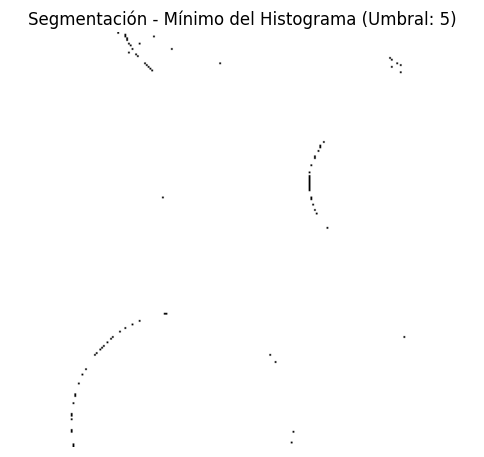

In [14]:
from scipy.signal import find_peaks 

# Encontrar picos en el histograma
picos, _ = find_peaks(histograma, distance=20)
print(f'Picos encontrados en el histograma: {picos[0]}, {picos[1]}')

minimo = np.argmin(histograma[picos[0]:picos[1]]) + picos[0] 
print(f'Umbral mínimo del histograma: {minimo}')

# Aplicar umbral
imagen_minimo = (imagen > minimo).astype(np.uint8) * 255 

# Mostrar la imagen segmentada
plt.figure(figsize=(6, 6))
plt.imshow(imagen_minimo, cmap='gray')
plt.title(f'Segmentación - Mínimo del Histograma (Umbral: {minimo})')
plt.axis('off')
plt.show()

### Usando la Media

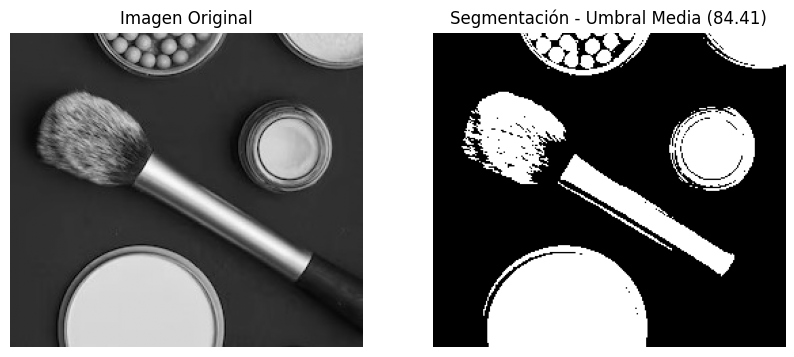

In [15]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Cargar la imagen en escala de grises
imagen = cv2.imread('imagen_makeup.jpg', cv2.IMREAD_GRAYSCALE)

# Calcular el umbral como la media de las intensidades
umbral_media = np.mean(imagen)

# Aplicar el umbral
imagen_media = (imagen >= umbral_media).astype(np.uint8) * 255

# Mostrar la imagen original y segmentada
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(imagen, cmap='gray')
plt.title('Imagen Original')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(imagen_media, cmap='gray')
plt.title(f'Segmentación - Umbral Media ({umbral_media:.2f})')
plt.axis('off')
plt.show()

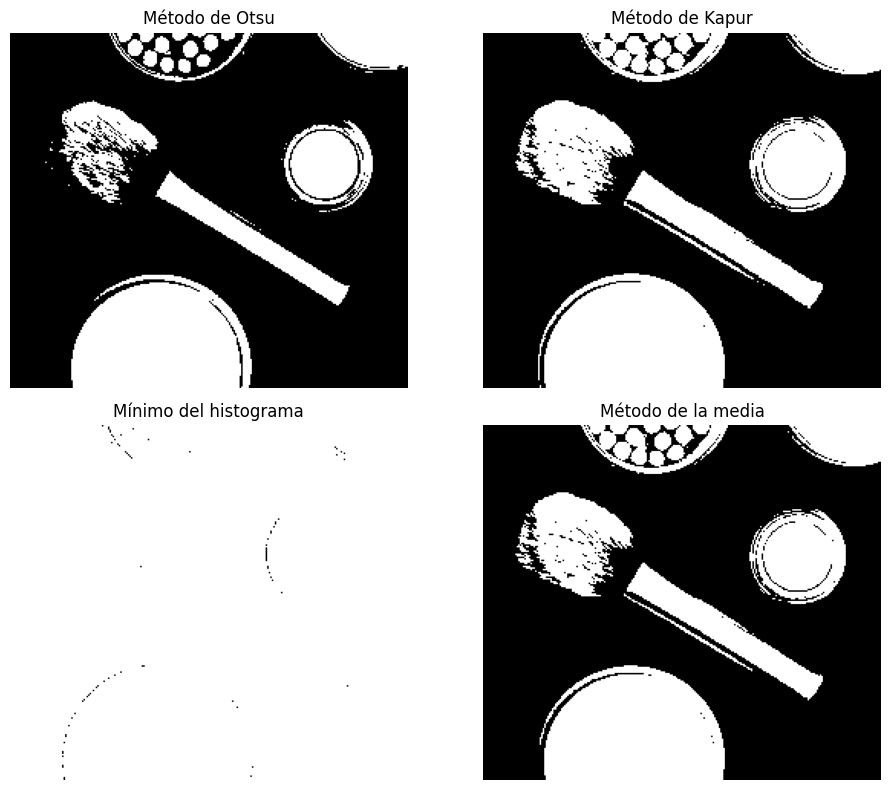

In [16]:
imagenes = [
    imagen_otsu,
    imagen_kapur,
    imagen_minimo,
    imagen_media
]

titulos = [
    'Método de Otsu',
    'Método de Kapur',
    'Mínimo del histograma',
    'Método de la media'
]

fig, ejes = plt.subplots(2, 2, figsize=(10, 8))

for eje, img, titulo in zip(ejes.flat, imagenes, titulos):
    eje.imshow(img, cmap='gray', vmin=0, vmax=255)
    eje.set_title(titulo)
    eje.axis('off')

plt.tight_layout()
plt.show()

### Multiple umbrales y umbral banda

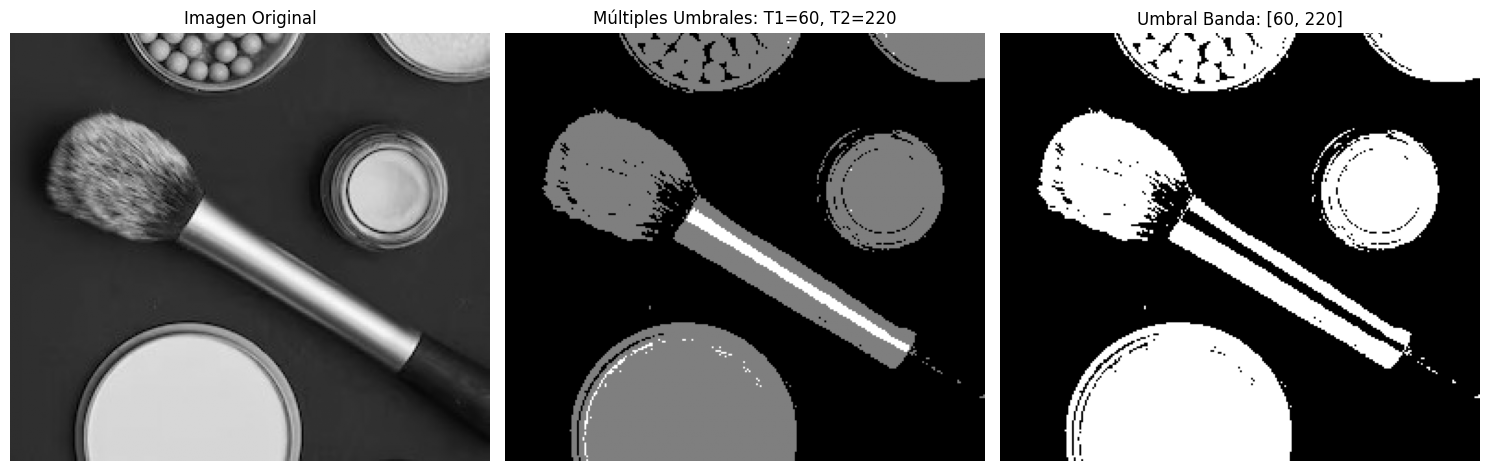

In [18]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
# Cargar la imagen en escala de grises
#imagen = cv2.imread('imagen_prueba.jpg', cv2.IMREAD_GRAYSCALE)
# Definir los umbrales, por ejemplo, estos valores
T1 = 60
T2 = 220

# Segmentación con dos umbrales (tres categorías)
imagen_multi_umbrales = np.zeros_like(imagen)
imagen_multi_umbrales[imagen < T1] = 0
imagen_multi_umbrales[(imagen >= T1) & (imagen < T2)] = 127
imagen_multi_umbrales[imagen >= T2] = 255

# Segmentación por umbral banda
imagen_umbral_banda = np.zeros_like(imagen)
imagen_umbral_banda[(imagen >= T1) & (imagen <= T2)] = 255

# Visualización de los resultados
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(imagen, cmap='gray')
plt.title('Imagen Original')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(imagen_multi_umbrales, cmap='gray')
plt.title(f'Múltiples Umbrales: T1={T1}, T2={T2}')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(imagen_umbral_banda, cmap='gray')
plt.title(f'Umbral Banda: [{T1}, {T2}]')
plt.axis('off')
plt.tight_layout()
plt.show()